# Baseline vs RBF sector

Comparacao das cadeias salvas, sem MCMC, reponderacao ou treinamento.

**Baseline vermelho tracejado; modelo setorizado azul.** O baseline e a reproducao JETSCAPE, nao a cadeia de referencia externa. Os caminhos, metadados e versoes constam em `comparison_manifest.json`.

## Amostragem e modelos

200.000 vetores por cadeia para parametros, stride 50 e nenhum descarte adicional de producao. O burn-in salvo separadamente nao entra nos graficos. Todas as amostras retidas sao finitas e estao dentro dos mesmos limites do design.

O modelo setorizado separa cada observavel/sistema e, nas regioes eta configuradas, o centro das laterais combinadas. CS usa rho=1; RBF usa comprimentos pt=0.5 GeV/c, eta=1, centralidade=10 pontos percentuais. A covariancia do emulador permanece no ajuste em ambos os casos.

## Parametros: mudancas descritivas

Delta = mediana setorizada - mediana baseline. A normalizacao usa a largura do intervalo central de 90% do baseline; nao e um teste de significancia. A razao de larguras e setor/baseline.

Maiores deslocamentos relativos: `bulk_viscosity_3_zeta_over_s_max` (+0.413), `shear_viscosity_3_eta_over_s_at_kink` (+0.253), `bulk_viscosity_3_zeta_over_s_width_in_GeV` (-0.228), `bulk_viscosity_3_zeta_over_s_lambda_asymm` (-0.216), `tau_form_mean` (-0.189).

| Parametro | Baseline mediana | Setor mediana | Delta / largura baseline 90% | Razao larguras 90% |
|---|---:|---:|---:|---:|
| ylossParam4At2 | 1.0112 | 0.9581 | -0.033 | 1.015 |
| ylossParam4At4 | 1.6777 | 1.6764 | -0.001 | 1.035 |
| ylossParam4At6 | 2.0541 | 2.0415 | -0.013 | 0.890 |
| ylossParam4var | 0.61487 | 0.58664 | -0.033 | 1.028 |
| remnant_energy_loss_fraction | 0.46723 | 0.46744 | +0.000 | 0.860 |
| shadowing_factor | 0.069345 | 0.092757 | +0.082 | 1.619 |
| tau_form_mean | 0.54122 | 0.40373 | -0.189 | 0.996 |
| BG | 7.4262 | 8.3564 | +0.046 | 1.008 |
| string_source_sigma_x | 0.20652 | 0.24952 | +0.119 | 1.018 |
| string_source_sigma_eta | 0.4755 | 0.40949 | -0.106 | 0.998 |
| stringTransverseShiftFrac | 0.47999 | 0.46504 | -0.017 | 0.999 |
| shear_viscosity_3_eta_over_s_T_kink_in_GeV | 0.21214 | 0.21295 | +0.006 | 0.997 |
| shear_viscosity_3_eta_over_s_low_T_slope_in_GeV | -0.84985 | -1.0162 | -0.063 | 0.930 |
| shear_viscosity_3_eta_over_s_high_T_slope_in_GeV | 0.77605 | 0.86717 | +0.034 | 0.970 |
| shear_viscosity_3_eta_over_s_at_kink | 0.10256 | 0.14149 | +0.253 | 0.955 |
| bulk_viscosity_3_zeta_over_s_max | 0.090346 | 0.14498 | +0.413 | 1.019 |
| bulk_viscosity_3_zeta_over_s_T_peak_in_GeV | 0.16202 | 0.13301 | -0.181 | 0.344 |
| bulk_viscosity_3_zeta_over_s_width_in_GeV | 0.08317 | 0.057455 | -0.228 | 0.923 |
| bulk_viscosity_3_zeta_over_s_lambda_asymm | -0.27546 | -0.54023 | -0.216 | 0.820 |
| eps_switch | 0.54596 | 0.53516 | -0.069 | 1.179 |


### Corner: marginais e contornos conjuntos sobrepostos

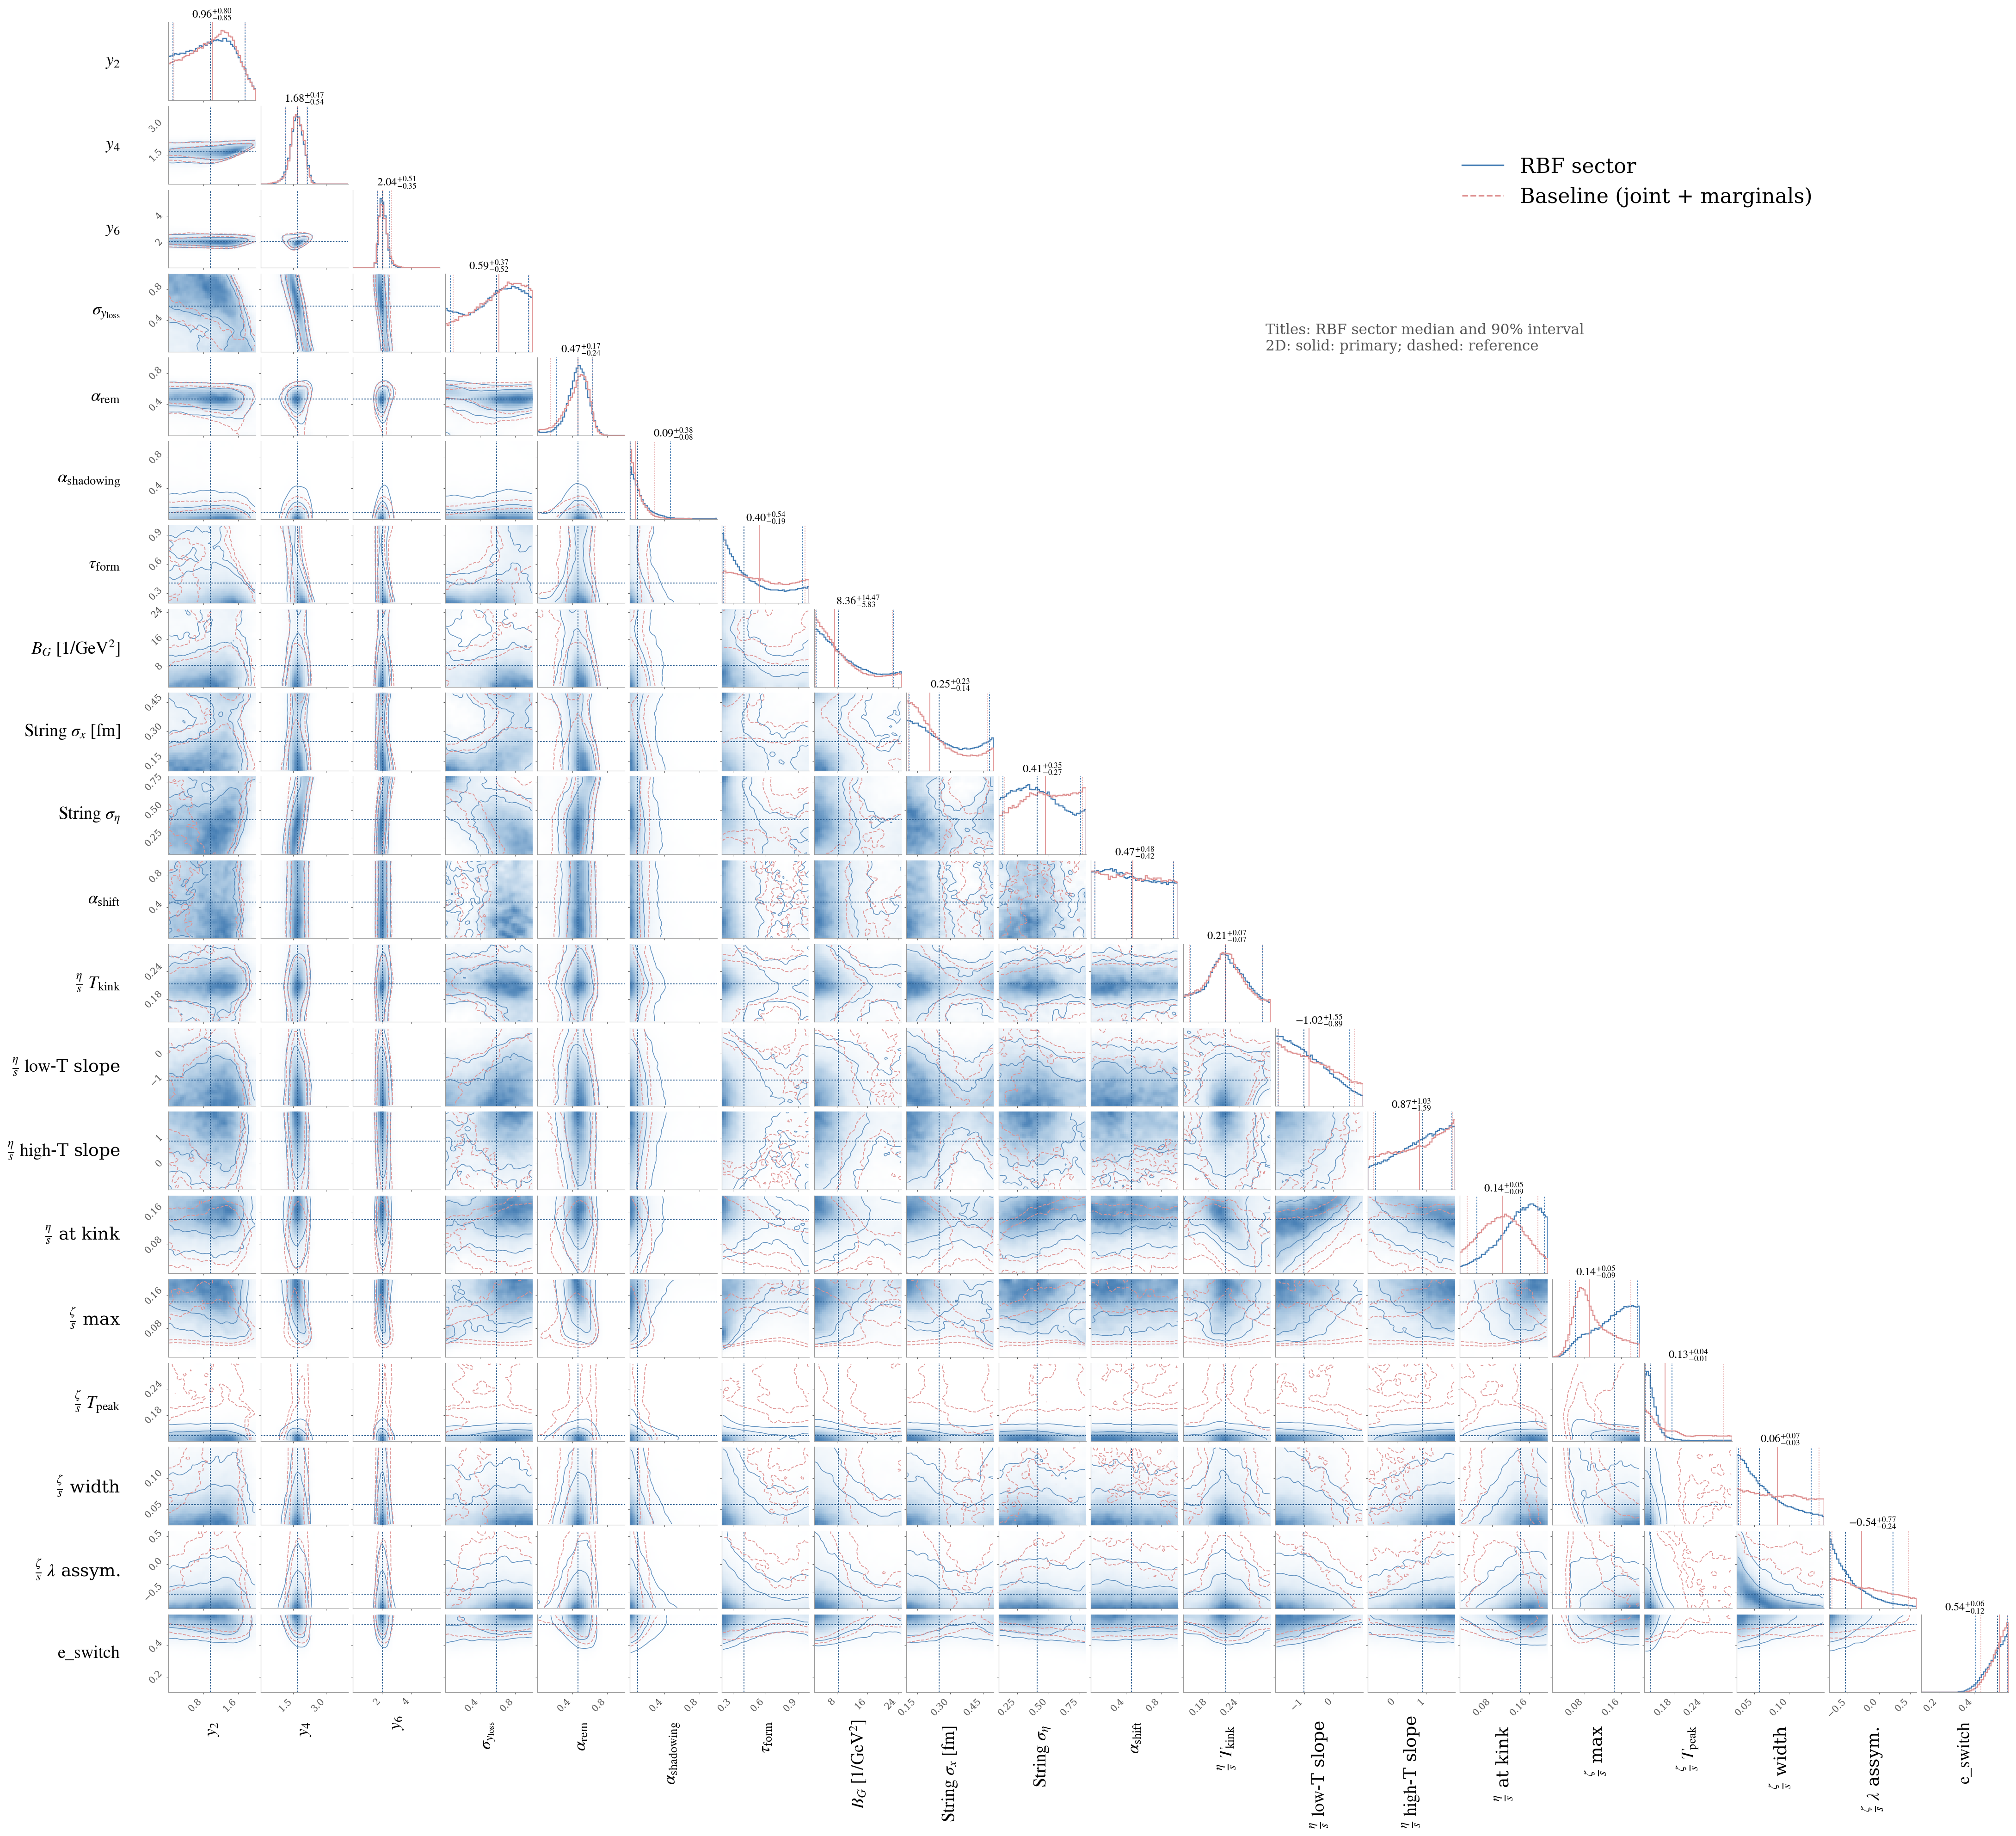

Arquivo: `posterior_corner_comparison.png`.

O corner mostra **ambas as cadeias tambem nos paineis 2D**: densidade/contornos azuis do setor e contornos vermelhos tracejados do baseline, com massas conjuntas de 68% e 90%. Titulos: mediana e intervalo central de 90% do setor.

### Comparacao das marginais

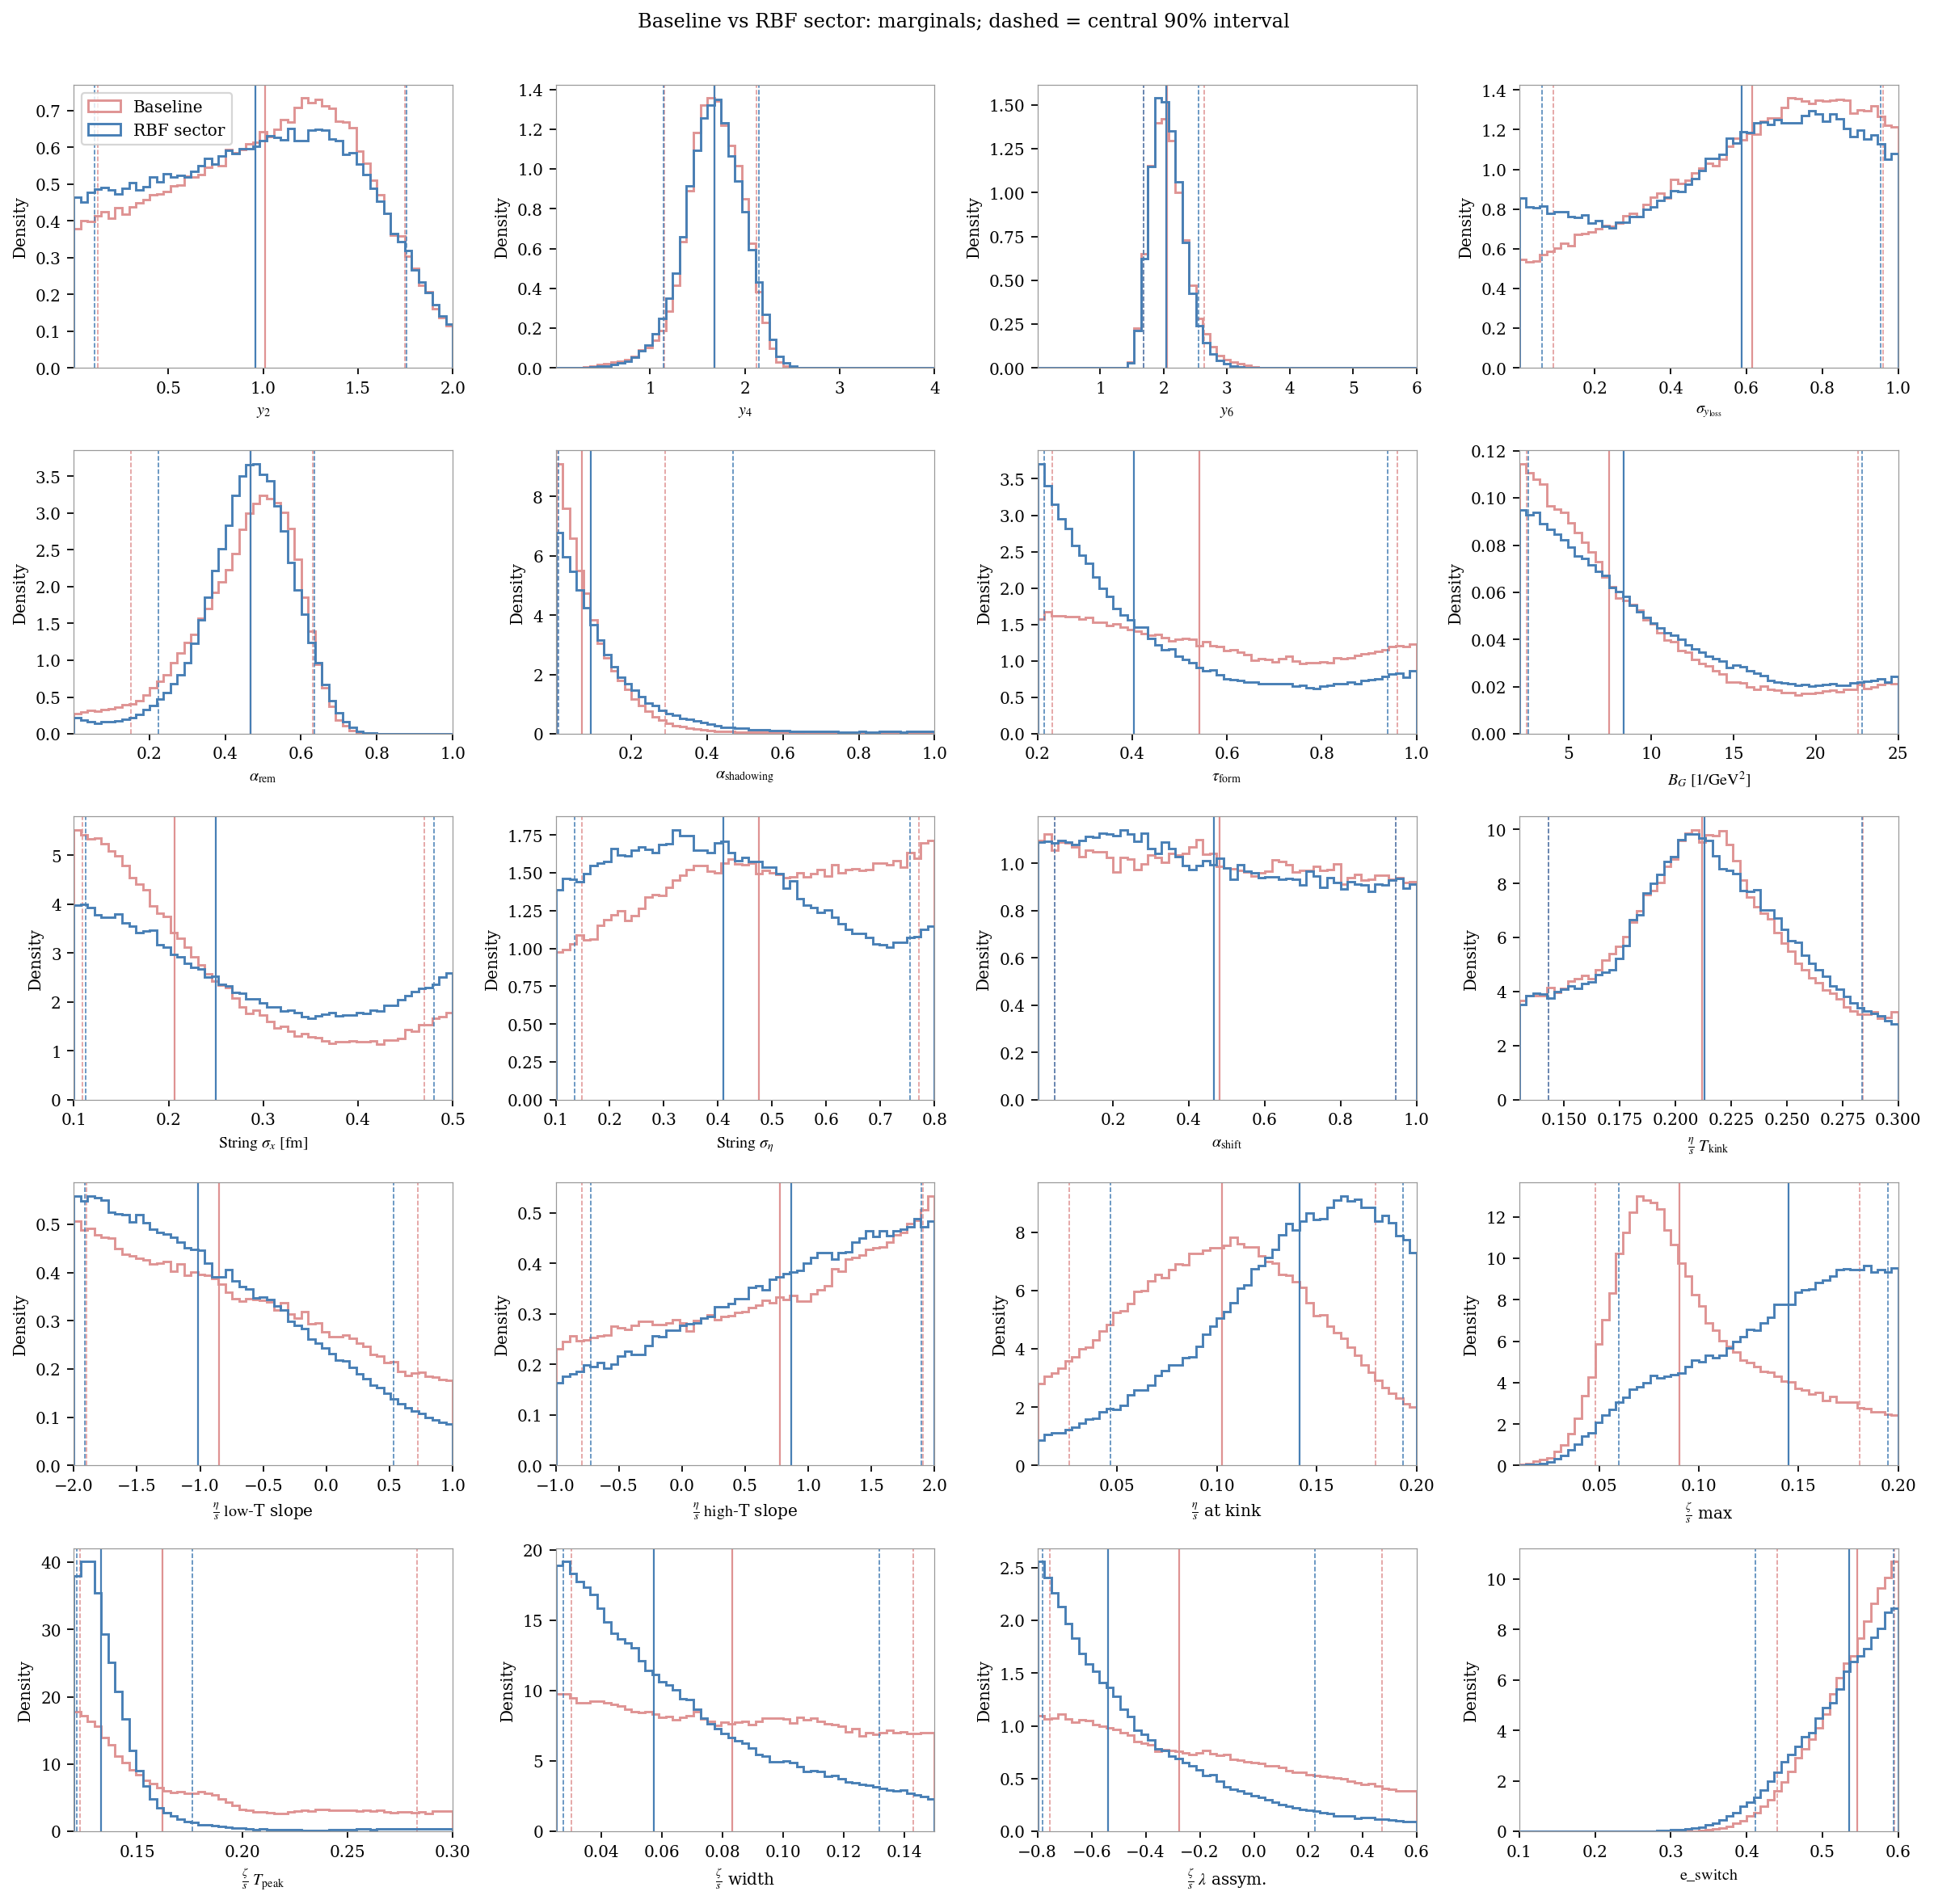

Arquivo: `posterior_marginals_comparison.png`.

## Previsoes dos observaveis

1.000 vetores de parametros por cadeia, com os mesmos indices walker/passo e seed de selecao 12345. As predicoes setorizadas reutilizam os arquivos auditados do estudo individual. As do baseline foram calculadas com os mesmos emuladores treinados. Parametros e indices usados estao salvos para verificacao.

Bandas: percentis 16-84 das **medias do emulador**, nao intervalos preditivos completos com ruido do emulador/experimento. Pontos pretos: dados experimentais com desvios padrao. Figuras individuais em `observables/` incluem painel model/data; paginas agrupadas abaixo mostram todos os 40 observaveis.

### posterior_comparison_Au-Au-200_page01

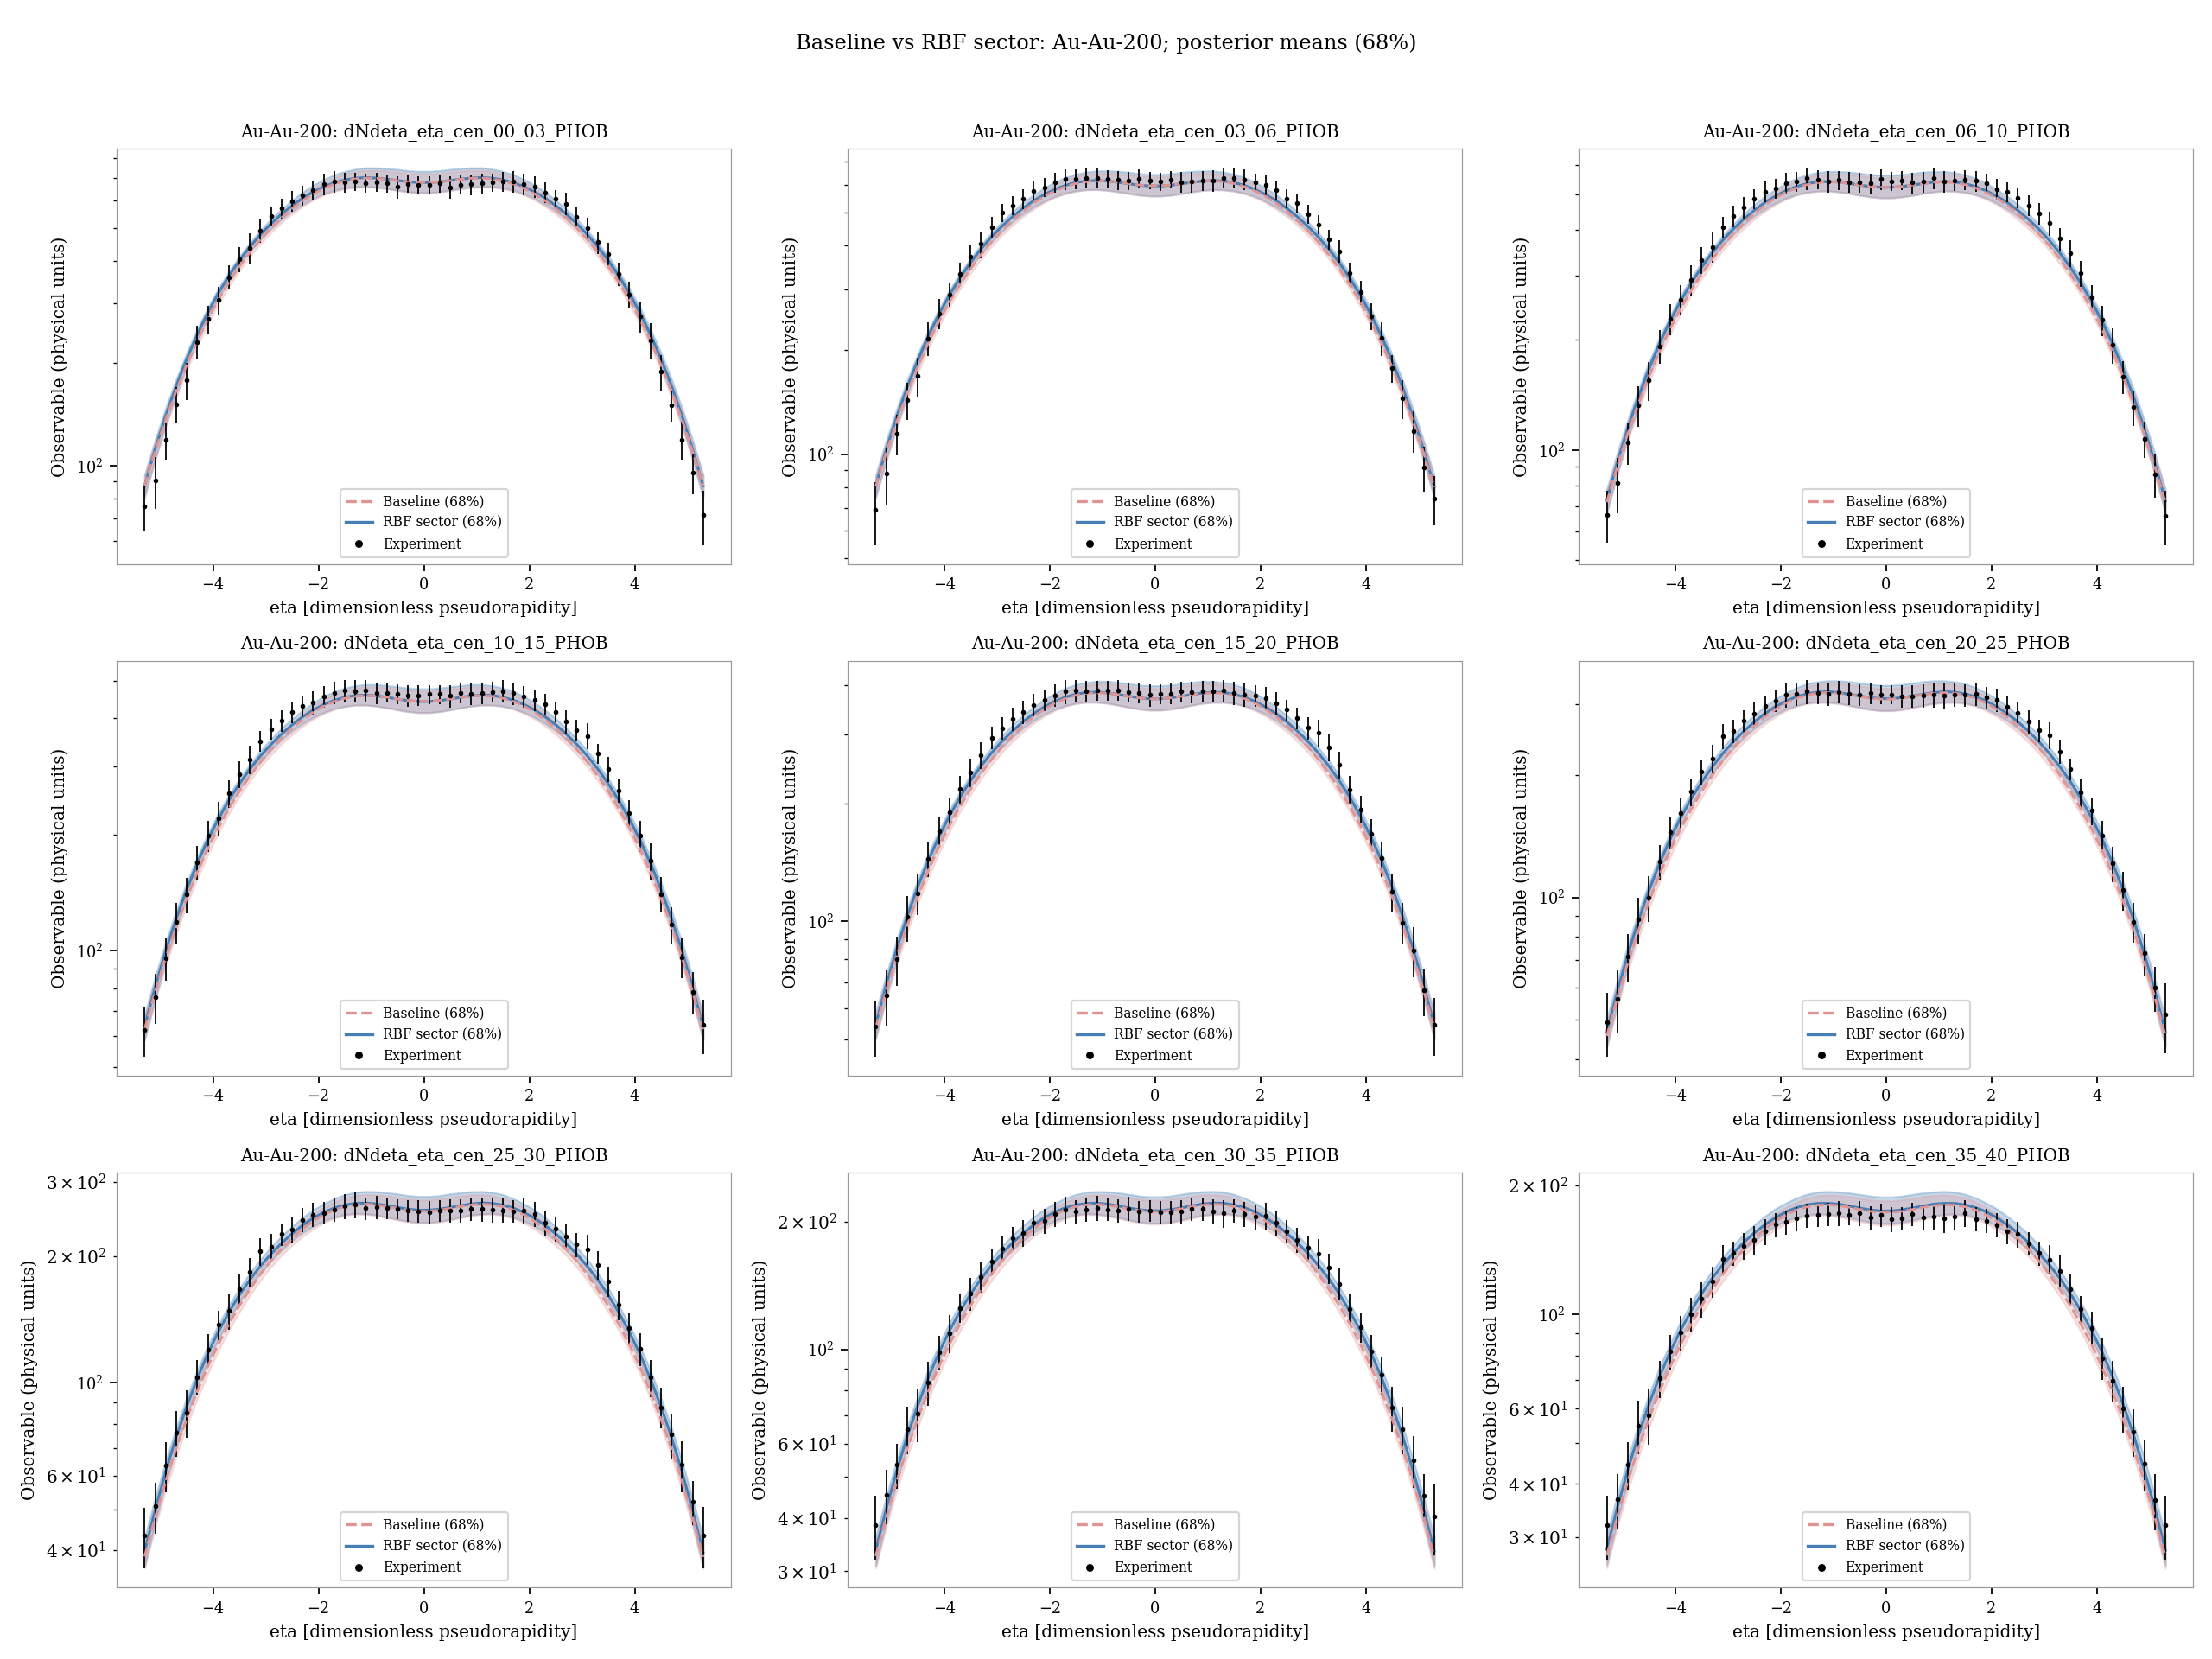

Arquivo: `observables/posterior_comparison_Au-Au-200_page01.png`.

### posterior_comparison_Au-Au-200_page02

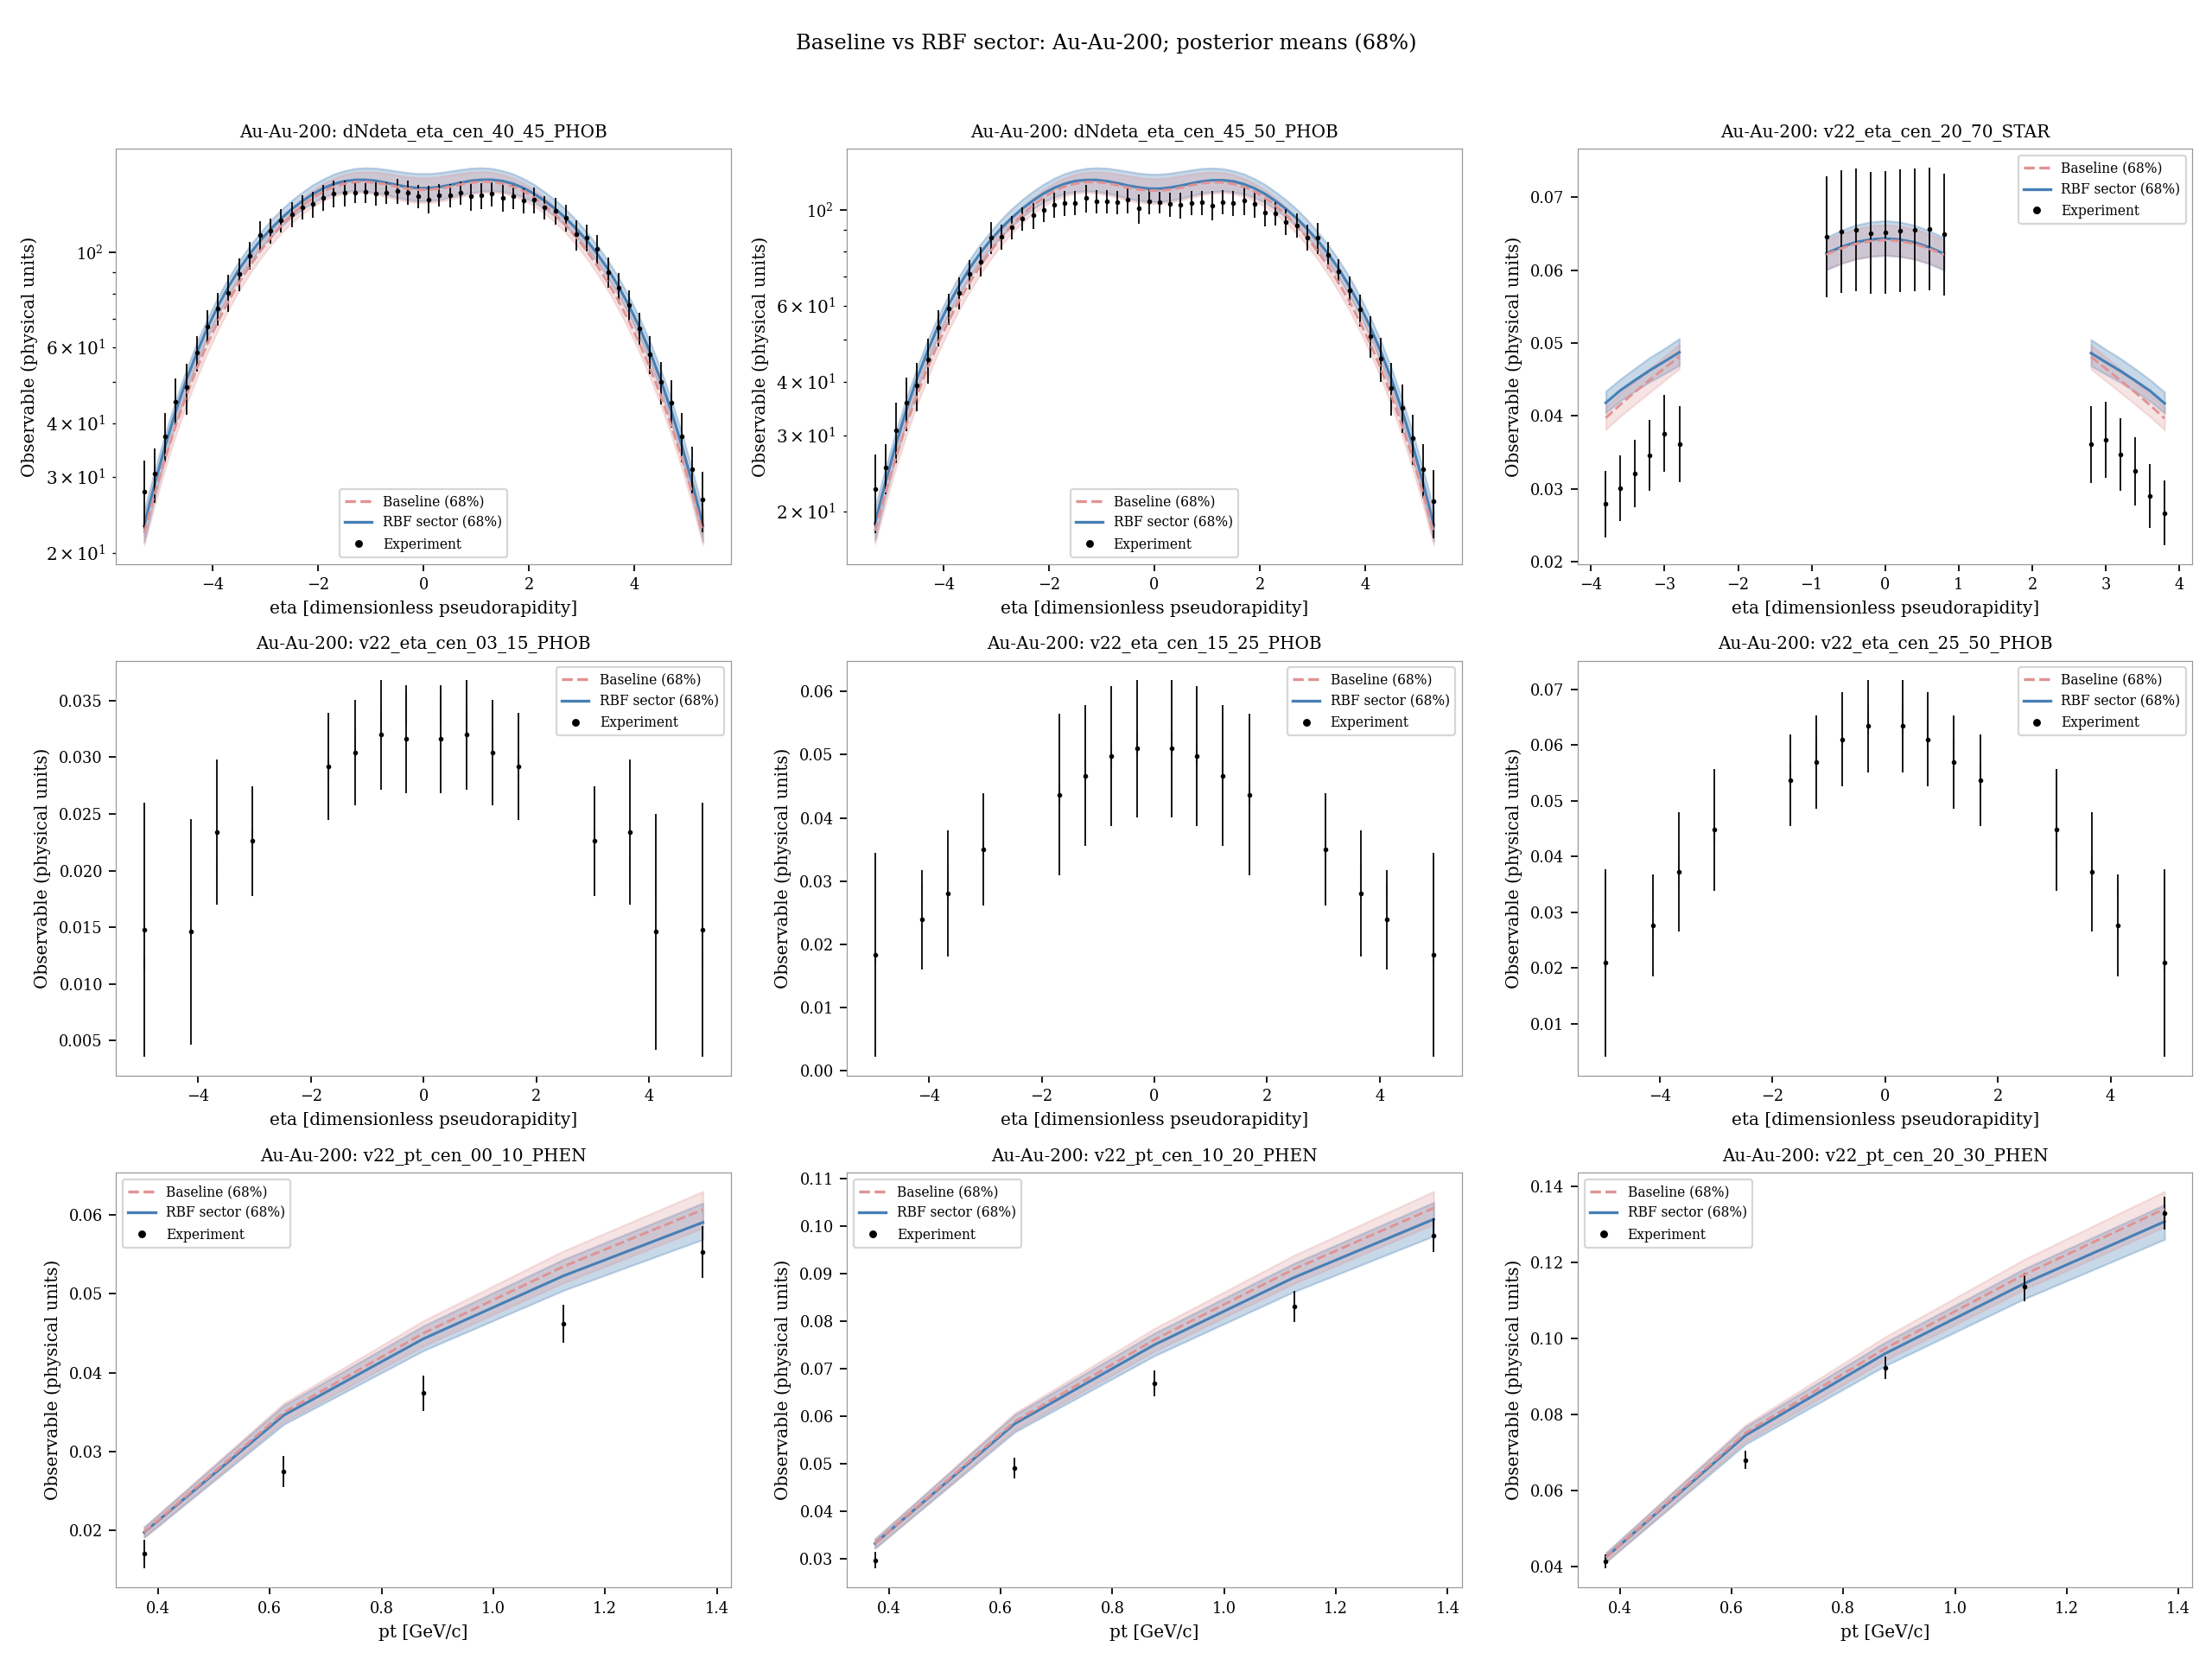

Arquivo: `observables/posterior_comparison_Au-Au-200_page02.png`.

### posterior_comparison_Au-Au-200_page03

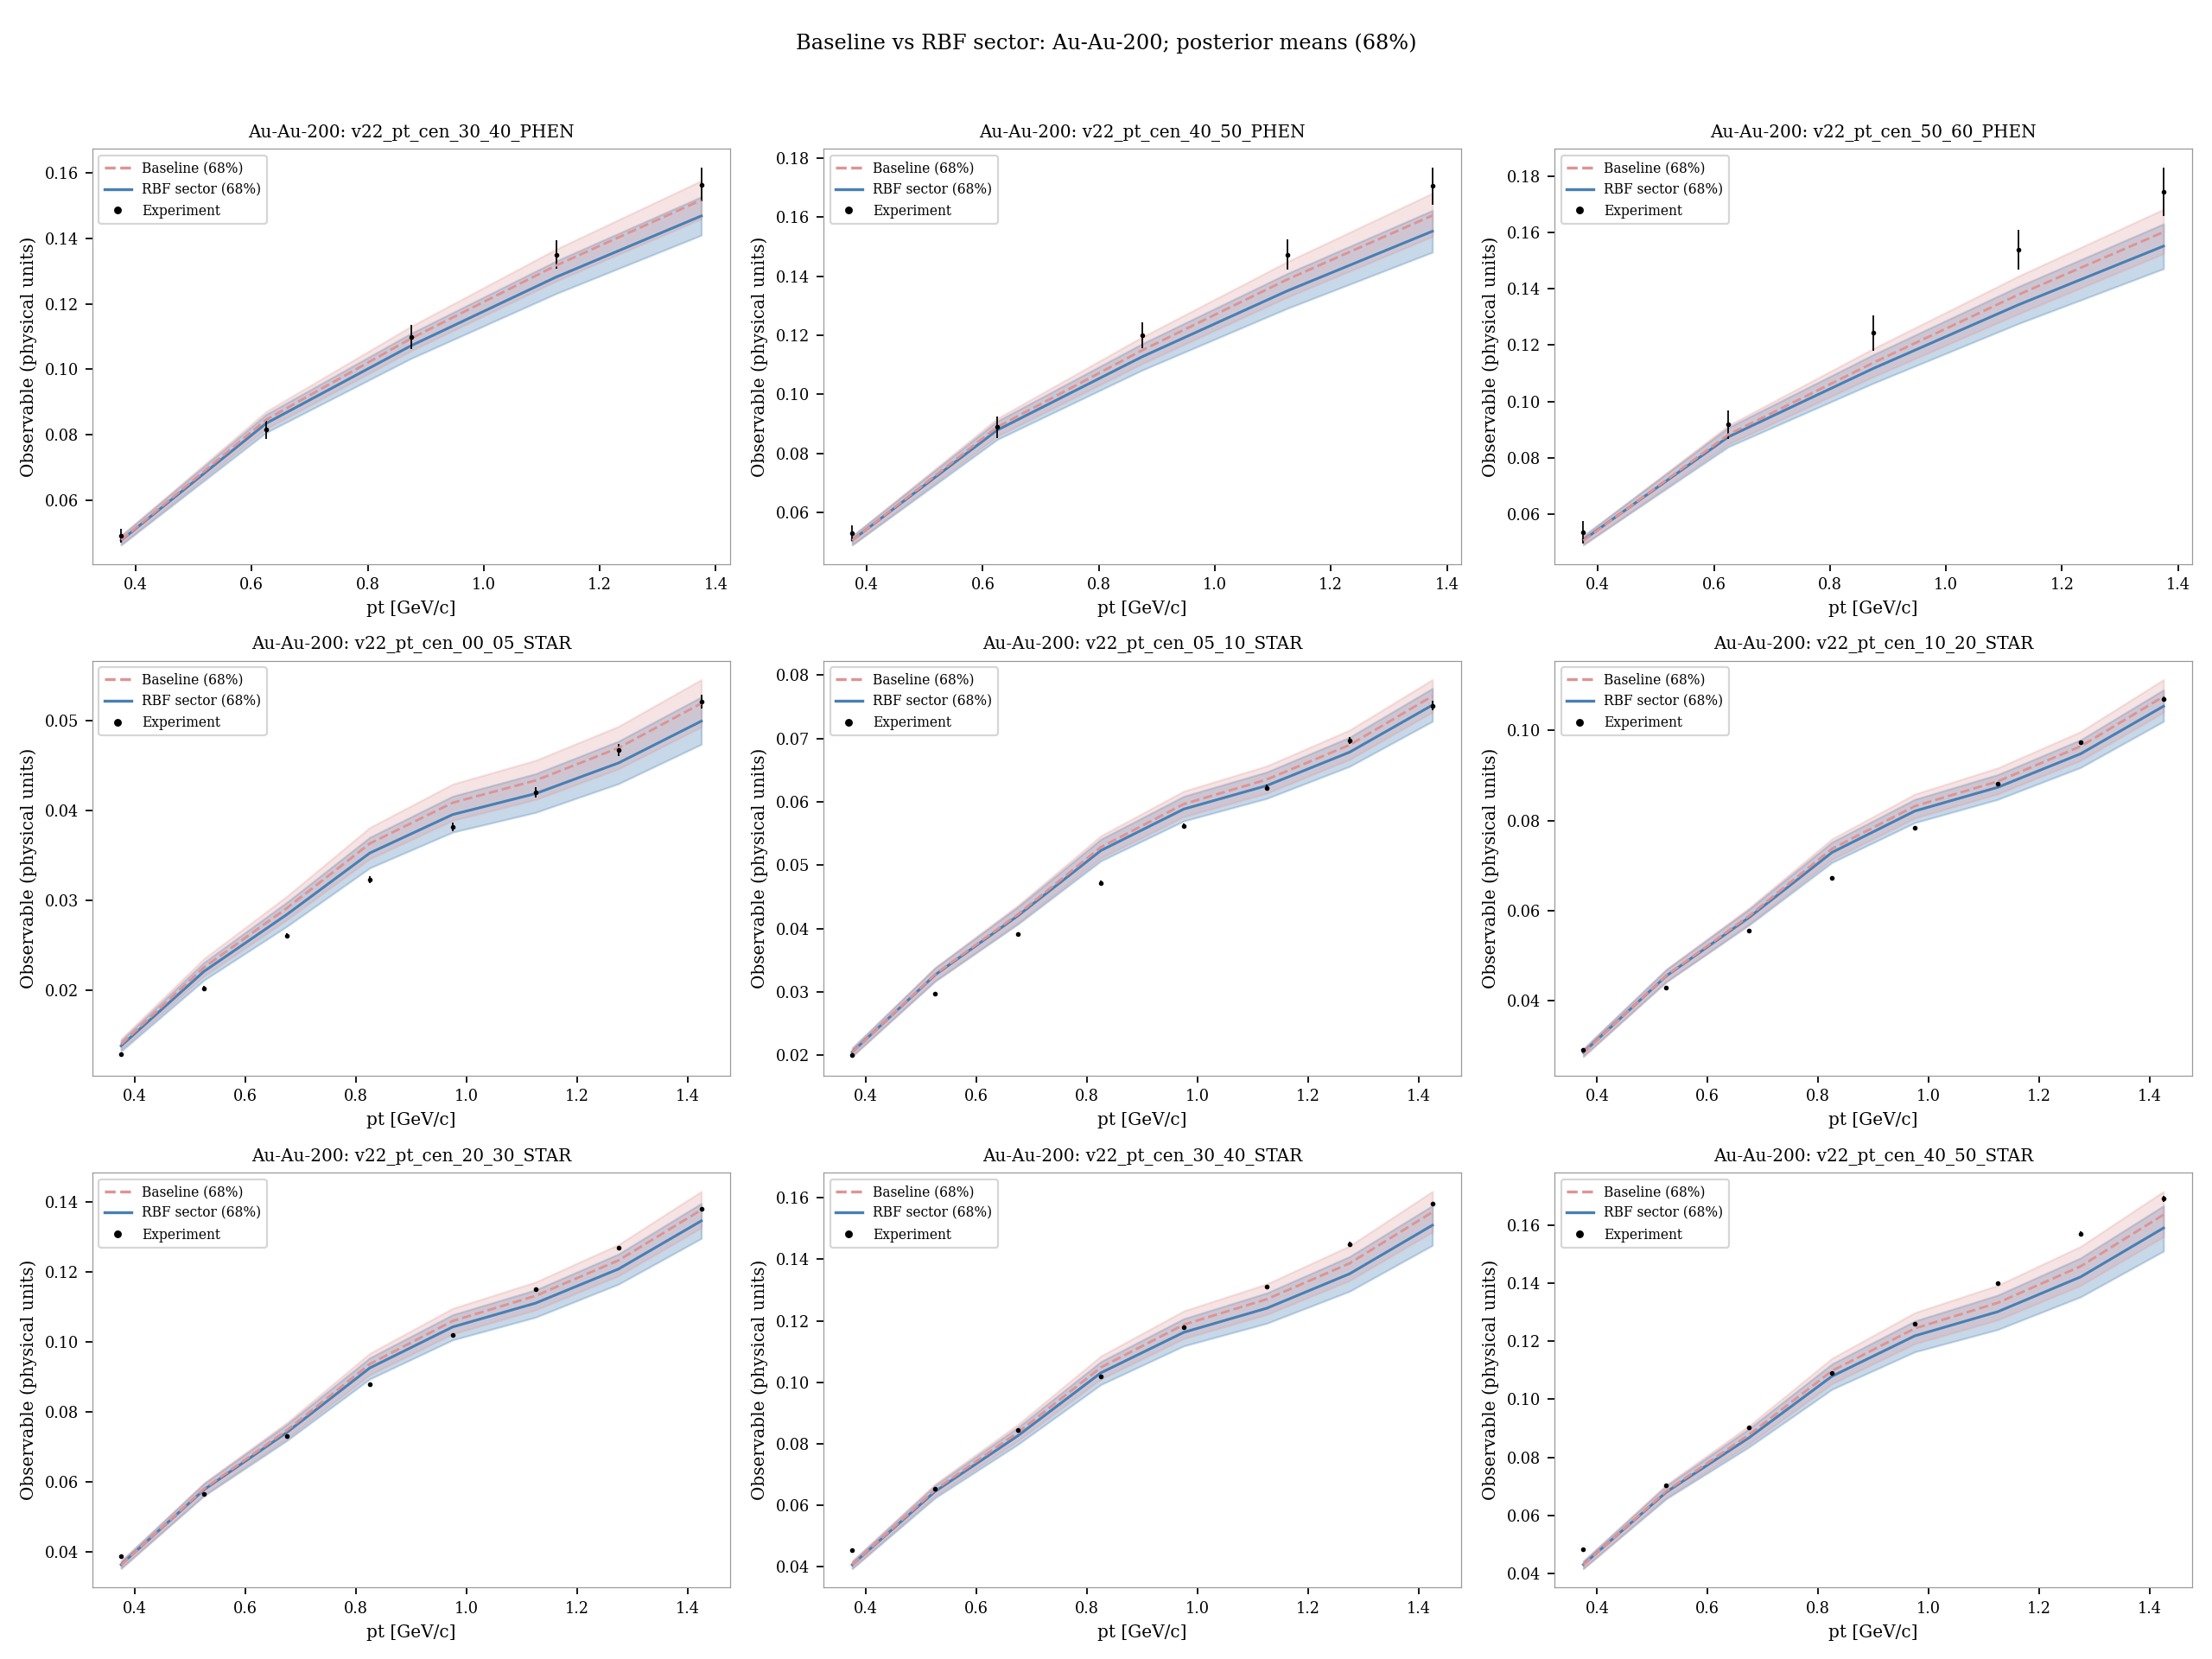

Arquivo: `observables/posterior_comparison_Au-Au-200_page03.png`.

### posterior_comparison_Au-Au-200_page04

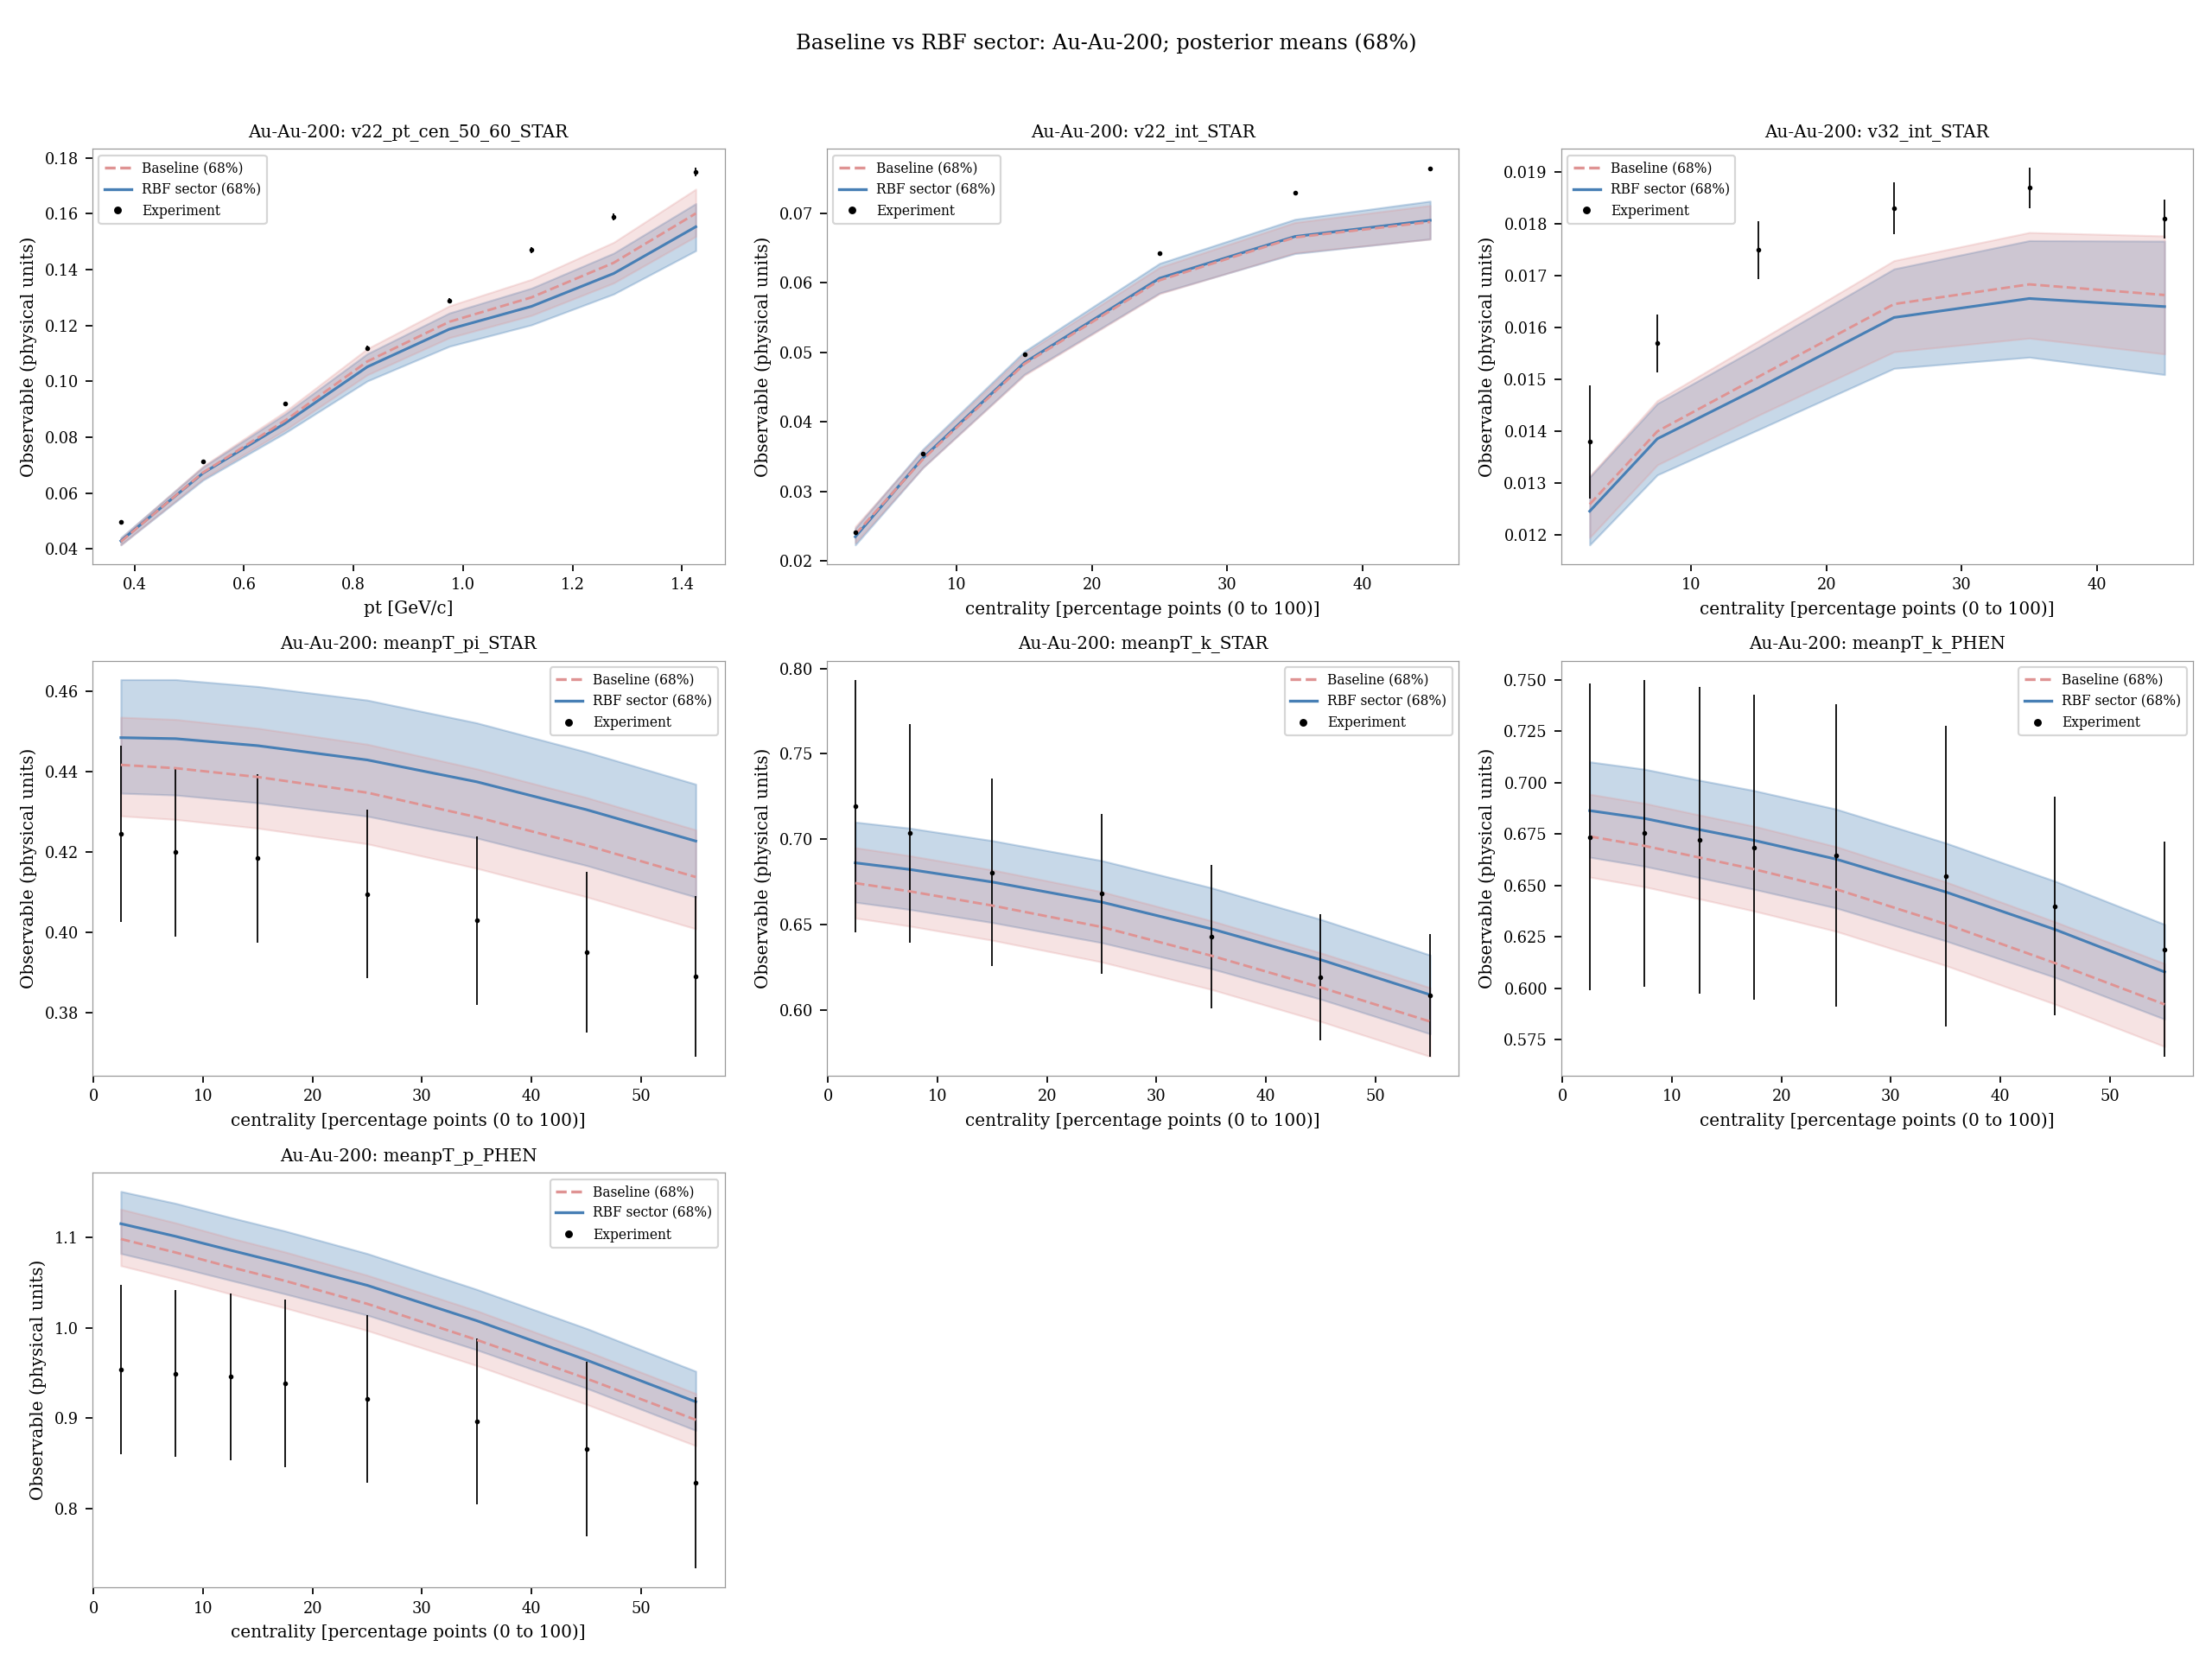

Arquivo: `observables/posterior_comparison_Au-Au-200_page04.png`.

### posterior_comparison_d-Au-200_page01

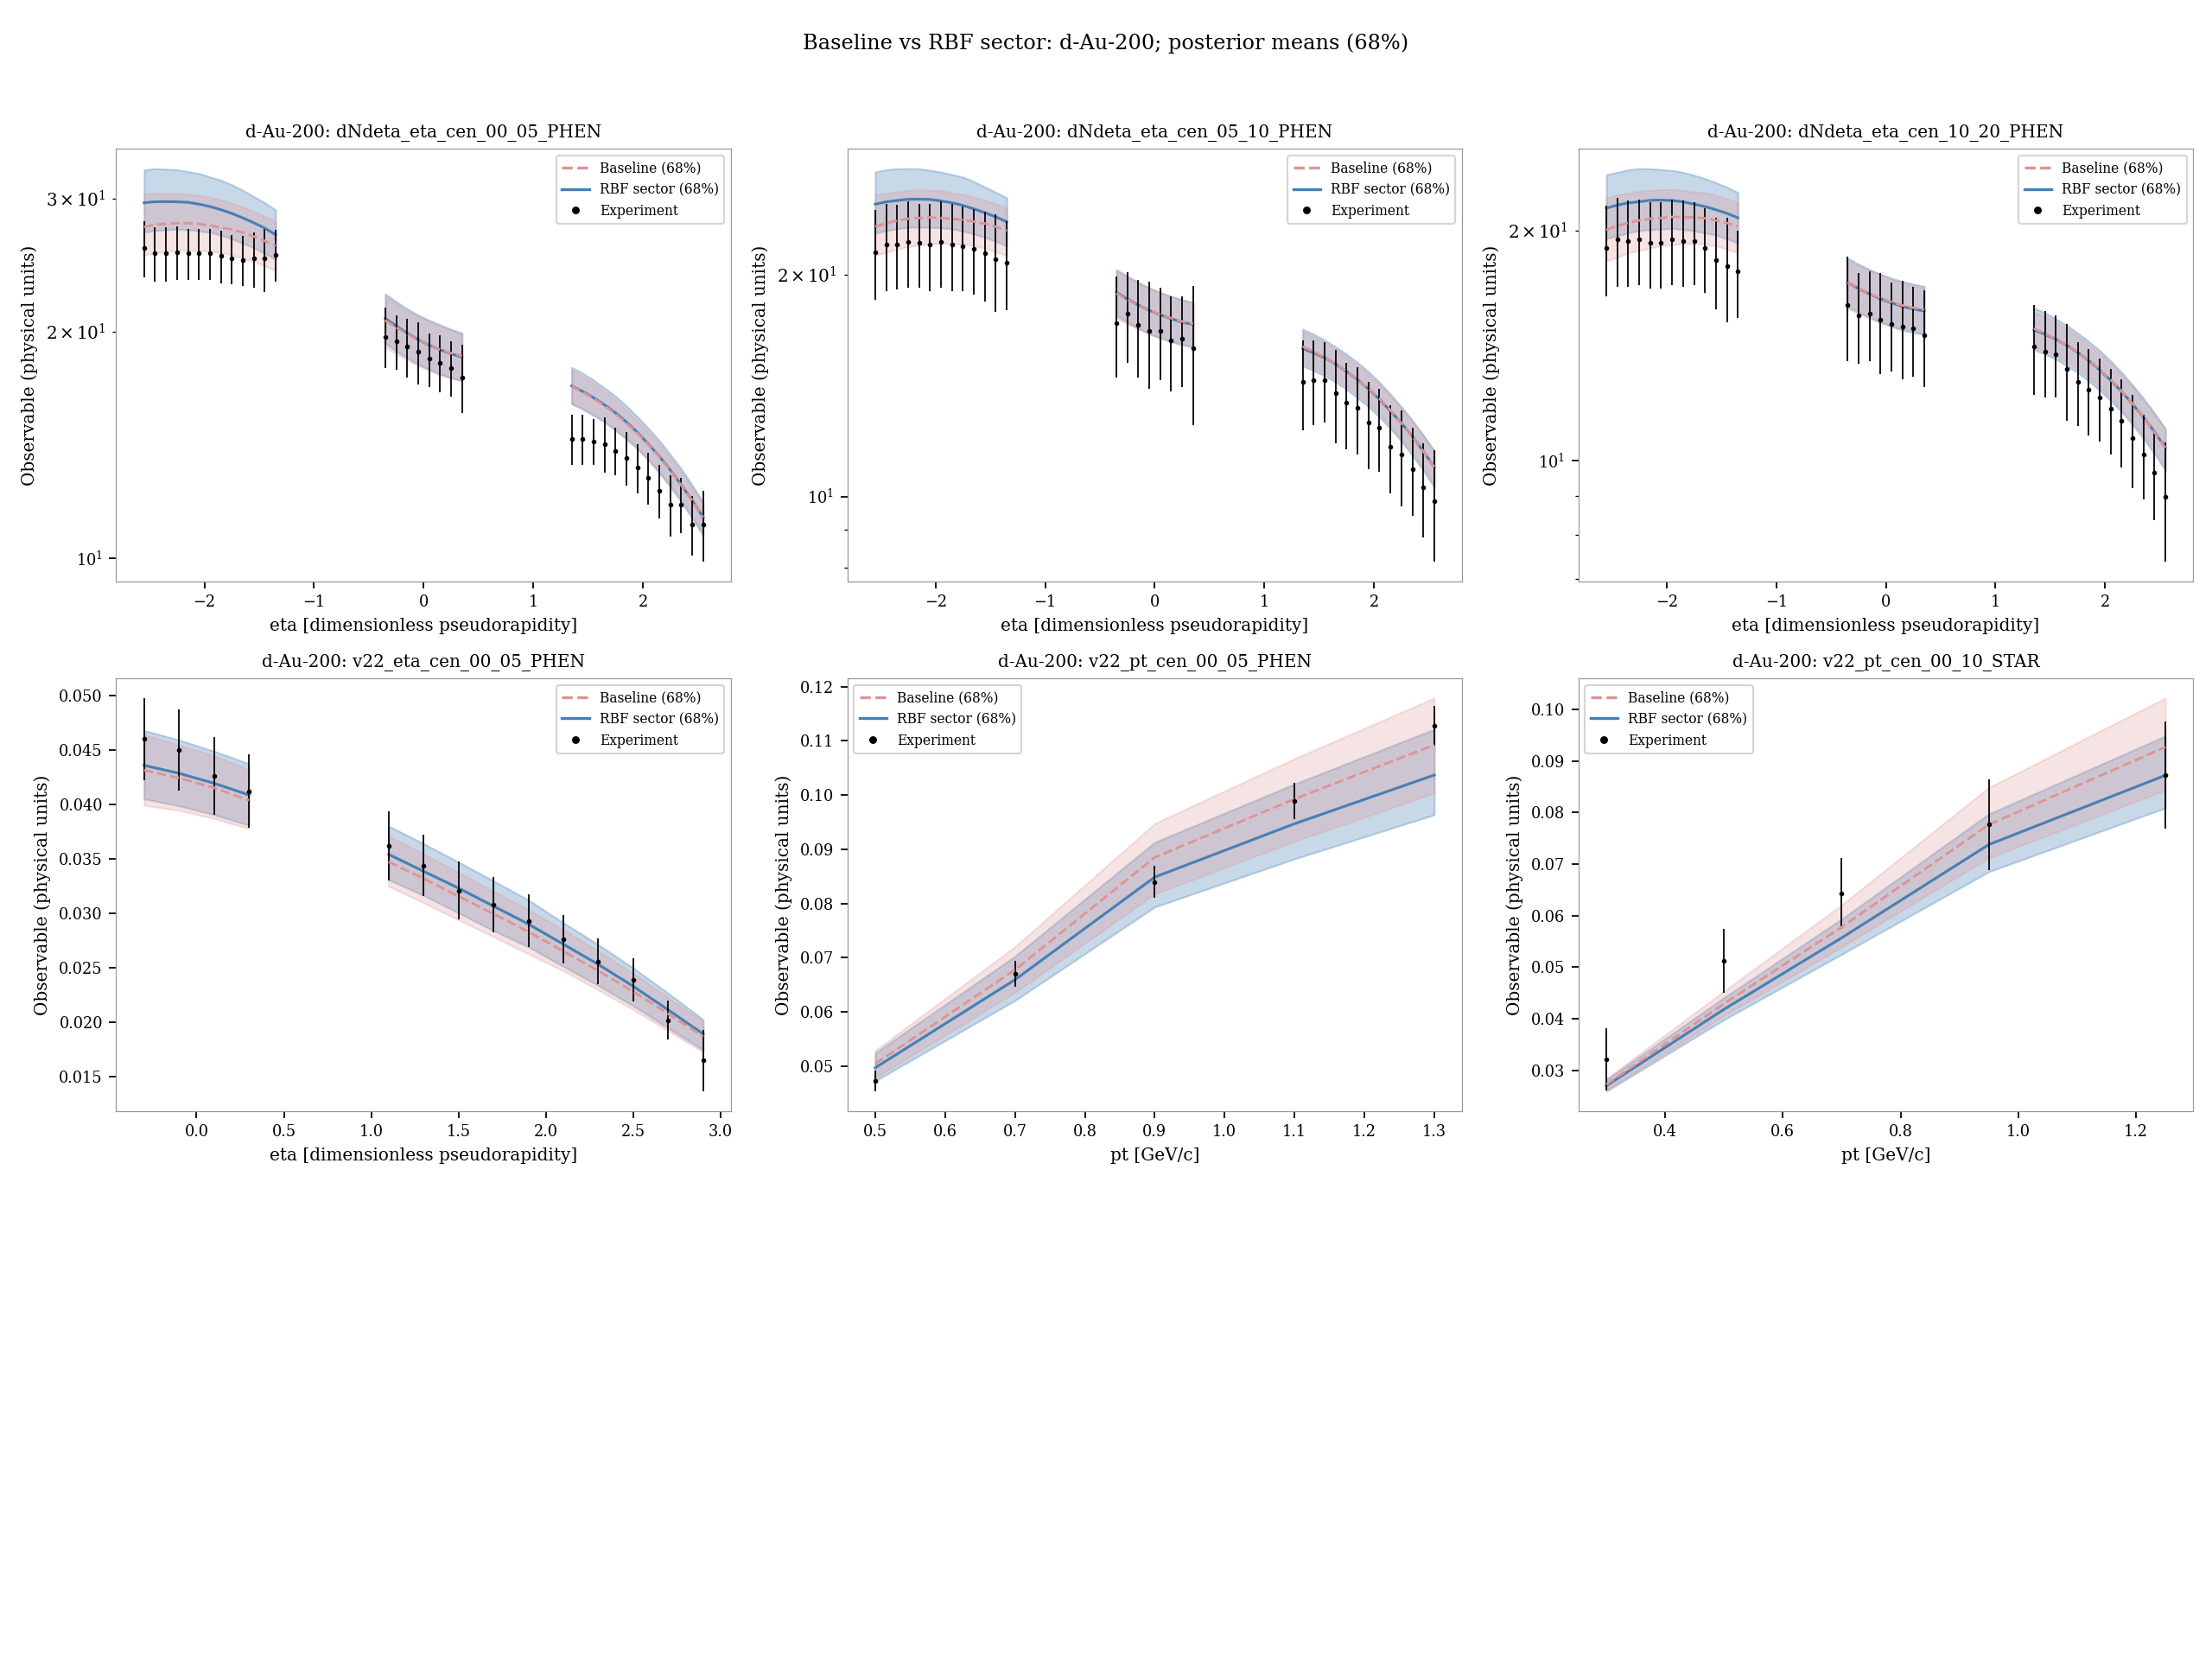

Arquivo: `observables/posterior_comparison_d-Au-200_page01.png`.

## Validacao e limites

Os indices de predicao foram confrontados diretamente com os HDF5 e as previsoes setorizadas com os CSVs existentes. Os emuladores foram validados contra os 40 observaveis historicos do estudo global CS (rtol=1e-6, atol=1e-10).

Os caches usam scikit-learn 1.6.1 e a leitura local 1.8.0. A validacao cobre as medias usadas nos graficos. O hash binario da covariancia local difere do registrado nas chains setorizadas, conforme documentado nos estudos originais; a causa permanece indeterminada. Nenhuma cadeia foi alterada nem reponderada. Nao foram calculados ESS/R-hat/autocorrelacao, nem evidencias ou Bayes factors.

Reproduzir da raiz do projeto:

```bash
python mcmc/scripts/build_sector_comparisons.py --model rbf
```